# Practica de Visualización

Un dataset de NOAA está almacenado en el archivo `data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv`. Este es el dataset que utilizaremos para la práctica.

Nota: Los datos para esta práctica forman parte de un dataset perteneciente a The data for this assignment comes from a subset of The National Centers for Environmental Information (NCEI) [Daily Global Historical Climatology Network](https://www1.ncdc.noaa.gov/pub/data/ghcn/daily/readme.txt) (GHCN-Daily). El GHCN-Daily se compone de registros climáticos diarios de miles de estaciones de la superficie terrestre en todo el mundo.

Cada fila en el archivo de datos corresponde a una sola observación.

Nos proporciona las siguientes variables:

- **id** : código de identificación de la estación
- **date** : fecha en formato YYYY-MM-DD (por ejemplo: 2012-01-24 = 24 de enero de 2012)
- **element** : indica el tipo de medición
    - **TMAX** : Temperatura máxima
    - **TMIN** : Temperatura mínima
- **value**: valor de la temperatura (en décimas de grados centígrados)

## Indicaciones

1. Lee la documentación y familiarícese con el conjunto de datos, luego escriba un código python que arroje un gráfico lineal de las temperaturas máximas y mínimas récord por día del año durante el período 2005-2014. El área entre las temperaturas máximas y mínimas récord de cada día debe estar sombreada.
2. Superponga una dispersión de los datos de 2015 para cualquier punto (máximos y mínimos) para los cuales se superó el récord de diez años (2005-2014) máximo o mínimo histórico en 2015.
3. Debes tener cuidado con los días bisiestos (es decir, el 29 de febrero), es totalmente razonable eliminar estos puntos del conjunto de datos para esta visualización.
4. ¡Haz que la imagen sea agradable! Considera problemas como leyendas, etiquetas y líneas en demasía.

Los datos proporcionados están cerca de **Ann Arbor, Michigan, Estados Unidos**.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Tu código a partir de aquí

## Parte 1.

In [19]:
ruta_csv = Path('../data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv')
if not ruta_csv.is_file():
    raise FileNotFoundError(f'No se encontró el archivo de datos: {ruta_csv.resolve()}')

df = pd.read_csv(ruta_csv)

columnas_requeridas = {'ID', 'Date', 'Element', 'Data_Value'}
columnas_faltantes = columnas_requeridas.difference(df.columns)
if columnas_faltantes:
    raise ValueError(f'Faltan columnas en el CSV: {sorted(columnas_faltantes)}')

df['Date'] = pd.to_datetime(df['Date'], errors='raise')
df['Data_Value'] = df['Data_Value'] / 10

print(f'Archivo cargado correctamente: {len(df):,} observaciones')
display(df.head())

Archivo cargado correctamente: 165,085 observaciones


,ID,Date,Element,Data_Value
0,USW00094889,2014-11-12,TMAX,2.2
1,USC00208972,2009-04-29,TMIN,5.6
2,USC00200032,2008-05-26,TMAX,27.8
3,USC00205563,2005-11-11,TMAX,13.9
4,USC00200230,2014-02-27,TMAX,-10.6


## Parte 2.

In [21]:
# Eliminar el 29 de febrero
df = df[~((df['Date'].dt.month == 2) & (df['Date'].dt.day == 29))].copy()

# Separar los datos históricos y los de 2015
hist = df[df['Date'].dt.year.between(2005, 2014)].copy()
datos2015 = df[df['Date'].dt.year == 2015].copy()

# Identificar el día y el mes
hist['Day'] = hist['Date'].dt.strftime('%m-%d')
datos2015['Day'] = datos2015['Date'].dt.strftime('%m-%d')

# Calcular los récords históricos
max_temp = hist[hist['Element'] == 'TMAX'].groupby('Day')['Data_Value'].max()
min_temp = hist[hist['Element'] == 'TMIN'].groupby('Day')['Data_Value'].min()

print(f'Parte 2 completada: {len(hist):,} observaciones históricas y {len(datos2015):,} de 2015')

Parte 2 completada: 151,245 observaciones históricas y 13,757 de 2015


## Parte 3.

In [17]:
# Obtener temperaturas máximas y mínimas de 2015
max_2015 = datos2015[datos2015['Element'] == 'TMAX'].copy()
min_2015 = datos2015[datos2015['Element'] == 'TMIN'].copy()

# Asociar cada temperatura con el récord histórico de ese día
max_2015['Record'] = max_2015['Day'].map(max_temp)
min_2015['Record'] = min_2015['Day'].map(min_temp)

# Filtrar los récords superados
max_break = max_2015[max_2015['Data_Value'] > max_2015['Record']]
min_break = min_2015[min_2015['Data_Value'] < min_2015['Record']]

print(f'Records superados en 2015: {len(max_break)} máximos y {len(min_break)} mínimos')

Records superados en 2015: 185 máximos y 174 mínimos


## Parte 4.

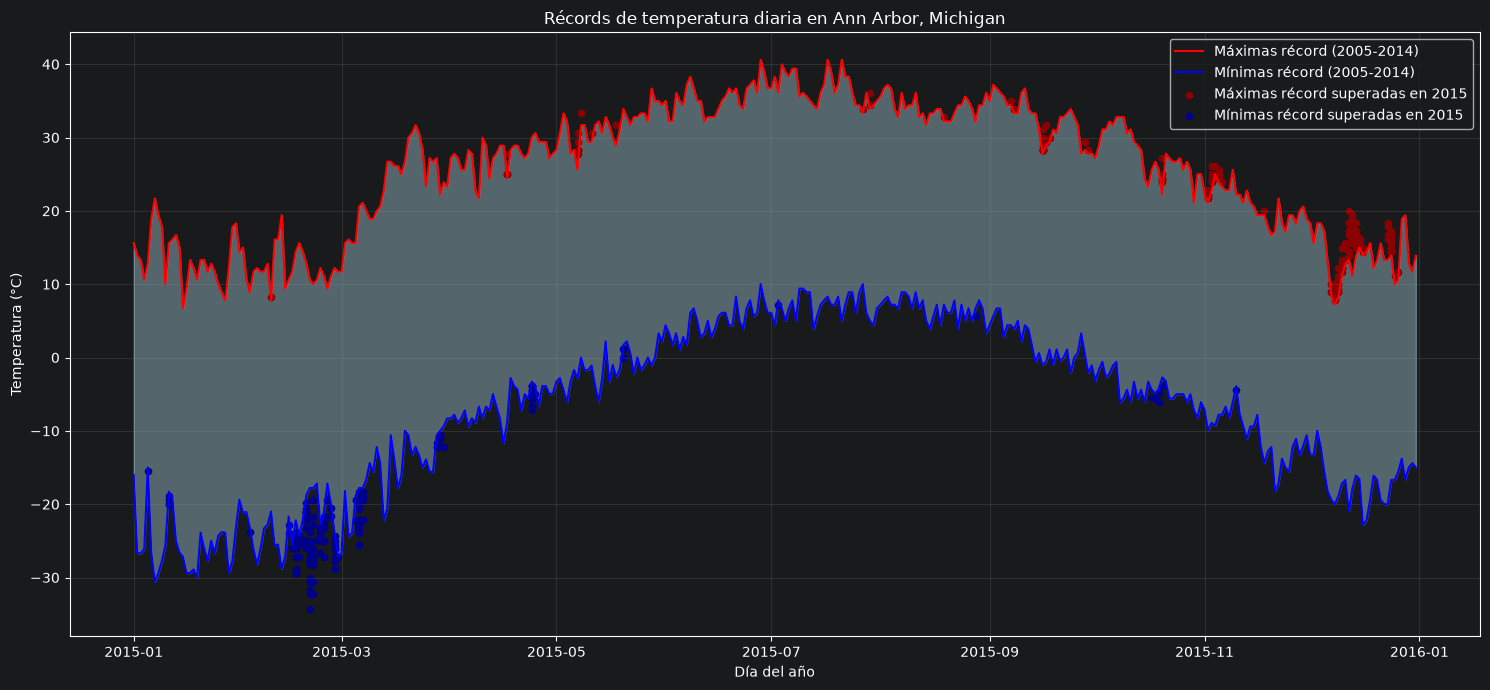

In [20]:
# Crear un calendario de 2015 para el eje horizontal
dates = pd.date_range("2015-01-01", "2015-12-31")
days = dates.strftime("%m-%d")

# Preparar los valores para las curvas
max_values = max_temp.reindex(days).values
min_values = min_temp.reindex(days).values

# Crear gráfico
plt.figure(figsize=(15, 7))

plt.plot(dates, max_values, color="red", label="Máximas récord (2005-2014)")
plt.plot(dates, min_values, color="blue", label="Mínimas récord (2005-2014)")

# Sombrear el área entre las curvas
plt.fill_between(dates, min_values, max_values, color="lightblue", alpha=0.4)

# Agregar los récords superados en 2015
plt.scatter(max_break["Date"], max_break["Data_Value"],
            color="darkred", label="Máximas récord superadas en 2015", s=20)

plt.scatter(min_break["Date"], min_break["Data_Value"],
            color="darkblue", label="Mínimas récord superadas en 2015", s=20)

plt.title("Récords de temperatura diaria en Ann Arbor, Michigan")
plt.xlabel("Día del año")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()